# Trabajo Práctico Integrador: Análisis de Churn en Telecomunicaciones (Telco)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LauritoFarias/tpi-analisis-de-datos/blob/main/notebooks/TPI_Analisis_de_Datos.ipynb)

**Materia:** Análisis de Datos

**Dataset:** Telco Customer Churn (Kaggle)

# A. Fundamentos, Ingesta y Limpieza de Datos

## 1. Configuración e Ingesta de Datos
* **Objetivo de negocio:** Identificar patrones de cancelación (*Churn*) en clientes de telecomunicaciones para reducir la tasa de baja.
* **Variables objetivo:** `Churn` (clasificación/fuga) y `TotalCharges` (regresión).
* **Hipótesis principales:** Mayor propensión de baja en contratos mensuales ($H_1$), en los primeros 6 meses de antigüedad ($H_2$) y en planes de Fibra Óptica con cargos elevados sin servicios de soporte ($H_3$). *(Ver desarrollo completo en `docs/INFORME_EJECUTIVO.pdf`).*

A continuación, se importan las bibliotecas y se realiza la ingesta directa del dataset estructurado (`.csv`).

In [1]:
# =============================================================================
# 1. CONFIGURACIÓN DEL ENTORNO E INGESTA DE DATOS
# =============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style="whitegrid", palette="muted")

RUTA_LOCAL = "../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

URL_GITHUB = "https://raw.githubusercontent.com/LauritoFarias/tpi-analisis-de-datos/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

if os.path.exists(RUTA_LOCAL):
    print(f"Cargando dataset desde entorno local: {RUTA_LOCAL}")
    df_raw = pd.read_csv(RUTA_LOCAL)
else:
    print("Entorno en la nube detectado (Colab). Cargando dataset desde GitHub...")
    df_raw = pd.read_csv(URL_GITHUB)

df = df_raw.copy()

print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
display(df.head(3))

Entorno en la nube detectado (Colab). Cargando dataset desde GitHub...
Dimensiones del dataset: 7043 filas y 21 columnas.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 2. Relevamiento de Variables vs. Tipos en Pandas (`dtypes`)
Se genera una tabla de auditoría para contrastar la clasificación estadística teórica de los 21 atributos frente a los tipos de datos asignados por defecto en Pandas (`dtypes`), identificando inconsistencias de tipado previo a la limpieza.

In [2]:
# =============================================================================
# 2. RELEVAMIENTO DE VARIABLES: CLASIFICACIÓN TEÓRICA VS PANDAS DTYPES
# =============================================================================

clasificacion_teorica = {
    'customerID': ('Cualitativa Nominal (Identificador)', 'Irrelevante para modelado'),
    'gender': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'SeniorCitizen': ('Cualitativa Nominal (Dicotómica: 0/1)', 'Explicativa'),
    'Partner': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'Dependents': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'tenure': ('Cuantitativa Discreta (Meses)', 'Explicativa'),
    'PhoneService': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'MultipleLines': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'InternetService': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'OnlineSecurity': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'OnlineBackup': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'DeviceProtection': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'TechSupport': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'StreamingTV': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'StreamingMovies': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'Contract': ('Cualitativa Ordinal (Mensual < 1 Año < 2 Años)', 'Explicativa'),
    'PaperlessBilling': ('Cualitativa Nominal (Dicotómica)', 'Explicativa'),
    'PaymentMethod': ('Cualitativa Nominal (Politómica)', 'Explicativa'),
    'MonthlyCharges': ('Cuantitativa Continua (Monetaria)', 'Explicativa'),
    'TotalCharges': ('Cuantitativa Continua (Monetaria)', 'Explicativa'),
    'Churn': ('Cualitativa Nominal (Dicotómica)', 'Variable Objetivo (Target)')
}

relevamiento_df = pd.DataFrame({
    'Columna': df.columns,
    'Tipo en Pandas (dtype)': df.dtypes.values,
    'Valores Nulos (NaN)': df.isnull().sum().values,
    'Valores Únicos': [df[col].nunique() for col in df.columns],
    'Clasificación Estadística Teórica': [clasificacion_teorica[col][0] for col in df.columns],
    'Rol en el Análisis': [clasificacion_teorica[col][1] for col in df.columns]
})

display(relevamiento_df)

,Columna,Tipo en Pandas (dtype),Valores Nulos (NaN),Valores Únicos,Clasificación Estadística Teórica,Rol en el Análisis
0,customerID,object,0,7043,Cualitativa Nominal (Identificador),Irrelevante para modelado
1,gender,object,0,2,Cualitativa Nominal (Dicotómica),Explicativa
2,SeniorCitizen,int64,0,2,Cualitativa Nominal (Dicotómica: 0/1),Explicativa
3,Partner,object,0,2,Cualitativa Nominal (Dicotómica),Explicativa
4,Dependents,object,0,2,Cualitativa Nominal (Dicotómica),Explicativa
5,tenure,int64,0,73,Cuantitativa Discreta (Meses),Explicativa
6,PhoneService,object,0,2,Cualitativa Nominal (Dicotómica),Explicativa
7,MultipleLines,object,0,3,Cualitativa Nominal (Politómica),Explicativa
8,InternetService,object,0,3,Cualitativa Nominal (Politómica),Explicativa
9,OnlineSecurity,object,0,3,Cualitativa Nominal (Politómica),Explicativa


## 3. Limpieza de Datos y Adecuación de Tipos
En este bloque se sanea la calidad del dataset ejecutando tres acciones:
1. **Detección de cadenas anómalas:** Se identifican 11 registros con espacios vacíos (`" "`) en `TotalCharges`.
2. **Imputación fundamentada:** Al verificarse que corresponden a clientes nuevos con antigüedad `tenure == 0`, se convierten a numérico (`float64`) e imputan con `0.0`.
3. **Conversión de `dtypes`:** Se recodifica `SeniorCitizen` a `Yes`/`No` y se transforman las variables cualitativas al tipo `category` (definiendo jerarquía ordinal para `Contract`).

In [3]:
# =============================================================================
# 3. LIMPIEZA DE DATOS, CADENAS ANÓMALAS Y ADECUACIÓN DE DTYPES
# =============================================================================

print("--- Auditoría de espacios en blanco (' ') ---")
for col in df.select_dtypes(include='object').columns:
    espacios = (df[col].str.strip() == "").sum()
    if espacios > 0:
        print(f"Columna '{col}': {espacios} registros con cadenas vacías.")

casos_anomalos = df[df['TotalCharges'].str.strip() == ""]
print("\nVerificación de antigüedad (tenure) en registros con TotalCharges vacío:")
display(casos_anomalos[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0.0)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'}).astype('category')

orden_contratos = pd.CategoricalDtype(categories=['Month-to-month', 'One year', 'Two year'], ordered=True)
df['Contract'] = df['Contract'].astype(orden_contratos)

cols_categoricas = [col for col in df.select_dtypes(include='object').columns if col != 'customerID']
for col in cols_categoricas:
    df[col] = df[col].astype('category')

print("\n--- Verificación de dtypes tras la adecuación ---")
print(df.dtypes)
print(f"\nTotal de valores nulos remanentes en el dataset: {df.isnull().sum().sum()}")

--- Auditoría de espacios en blanco (' ') ---
Columna 'TotalCharges': 11 registros con cadenas vacías.

Verificación de antigüedad (tenure) en registros con TotalCharges vacío:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No



--- Verificación de dtypes tras la adecuación ---
customerID            object
gender              category
SeniorCitizen       category
Partner             category
Dependents          category
tenure                 int64
PhoneService        category
MultipleLines       category
InternetService     category
OnlineSecurity      category
OnlineBackup        category
DeviceProtection    category
TechSupport         category
StreamingTV         category
StreamingMovies     category
Contract            category
PaperlessBilling    category
PaymentMethod       category
MonthlyCharges       float64
TotalCharges         float64
Churn               category
dtype: object

Total de valores nulos remanentes en el dataset: 0


## 4. Detección de Valores Atípicos (Método IQR)
Se calculan los límites del Rango Intercuartílico ($Q_1 - 1.5 \times \text{IQR}$ y $Q_3 + 1.5 \times \text{IQR}$) y se grafican los *Boxplots* para las variables numéricas (`tenure`, `MonthlyCharges`, `TotalCharges`). Al no registrarse valores fuera de los umbrales teóricos (0% outliers), se conserva la totalidad de los registros.

,Variable,Q1 (25%),Mediana (50%),Q3 (75%),IQR,Límite Inferior,Límite Superior,Cant. Outliers,% Outliers
0,tenure,9.00,29.00,55.00,46.00,-60.00,124.00,0,0.00
1,MonthlyCharges,35.50,70.35,89.85,54.35,-46.02,171.38,0,0.00
2,TotalCharges,398.55,1394.55,3786.60,3388.05,-4683.52,8868.67,0,0.00


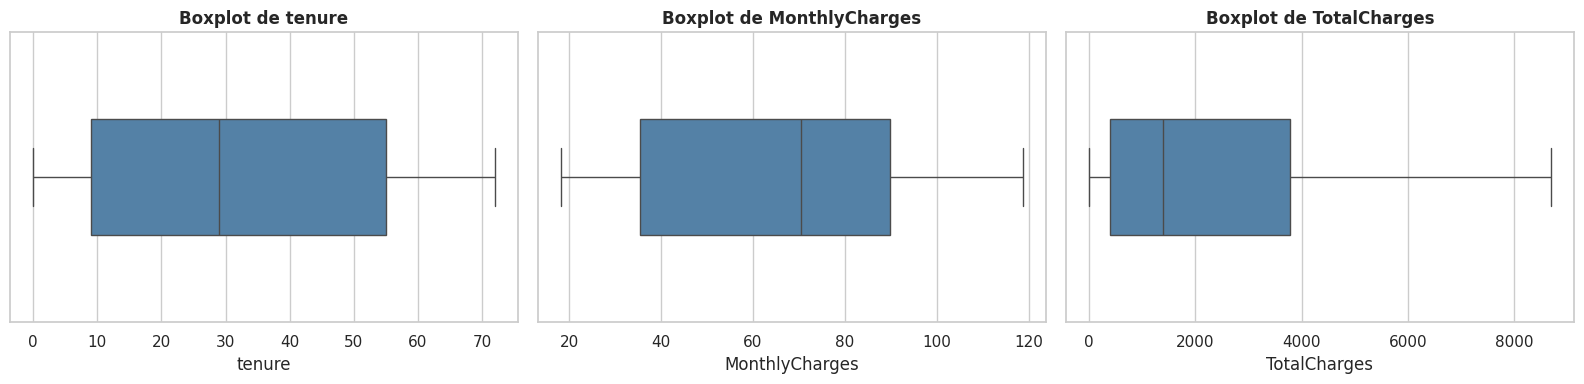

In [4]:
# =============================================================================
# 4. DETECCIÓN ANALÍTICA Y VISUAL DE VALORES ATÍPICOS (MÉTODO IQR)
# =============================================================================

variables_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']

resumen_iqr = []

for col in variables_numericas:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = df[(df[col] < limite_inferior) | (df[col] > limite_superior)]

    resumen_iqr.append({
        'Variable': col,
        'Q1 (25%)': Q1,
        'Mediana (50%)': df[col].median(),
        'Q3 (75%)': Q3,
        'IQR': IQR,
        'Límite Inferior': limite_inferior,
        'Límite Superior': limite_superior,
        'Cant. Outliers': len(outliers),
        '% Outliers': (len(outliers) / len(df)) * 100
    })

df_iqr = pd.DataFrame(resumen_iqr)
display(df_iqr)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(variables_numericas):
    sns.boxplot(x=df[col], ax=axes[i], color='steelblue', width=0.4)
    axes[i].set_title(f'Boxplot de {col}', fontweight='bold')
    axes[i].set_xlabel(col)

plt.tight_layout()
plt.show()

## 5. Manipulación de Datos: Transformación, Filtrado y Agregación

Con el dataset limpio y tipificado, se ejecutan las operaciones requeridas de manipulación en Pandas:
* **Transformación:** Eliminación del identificador irrelevante (`customerID`), creación de columnas calculadas (`TheoreticalTotalCharges`, `BillingVariance`, `AvgHistoricalMonthlyCharge`) y demostración de renombrado de atributos.
* **Filtrado avanzado:** Aislamiento del segmento crítico de fuga combinando condiciones lógicas.
* **Agregación (`groupby`):** Resumen estadístico multidimensional (conteo, suma, media, mediana y tasa de *Churn*) segmentado por tipo de contrato y servicio de internet.

In [5]:
# =============================================================================
# 4. MANIPULACIÓN DE DATOS: TRANSFORMACIÓN, FILTRADO Y AGREGACIÓN
# =============================================================================

if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)

df['TheoreticalTotalCharges'] = df['tenure'] * df['MonthlyCharges']
df['BillingVariance'] = df['TotalCharges'] - df['TheoreticalTotalCharges']

df['AvgHistoricalMonthlyCharge'] = np.where(
    df['tenure'] > 0,
    df['TotalCharges'] / df['tenure'],
    df['MonthlyCharges']
)

df['Churn_Binary'] = (df['Churn'] == 'Yes').astype(int)

df.rename(columns={
    'tenure': 'TenureMonths',
    'SeniorCitizen': 'IsSeniorCitizen'
}, inplace=True)
display(df[['TenureMonths', 'MonthlyCharges', 'TotalCharges', 'TheoreticalTotalCharges', 'BillingVariance']].head())

filtro_alto_riesgo = (
    (df['Contract'] == 'Month-to-month') &
    (df['InternetService'] == 'Fiber optic') &
    ((df['MonthlyCharges'] > 70) | (df['TenureMonths'] < 6)) &
    (df['Churn'] == 'Yes')
)

df_segmento_critico = df[filtro_alto_riesgo]
print(f"Clientes en el segmento crítico filtrado: {len(df_segmento_critico)} ({len(df_segmento_critico)/len(df)*100:.2f}% del total)")
display(df_segmento_critico[['IsSeniorCitizen', 'TenureMonths', 'InternetService', 'Contract', 'MonthlyCharges', 'TotalCharges']].head())

resumen_negocio = df.groupby(['Contract', 'InternetService'], observed=False).agg(
    Total_Clientes=('Churn', 'count'),
    Clientes_Perdidos=('Churn_Binary', 'sum'),
    Tasa_Churn_Pct=('Churn_Binary', lambda x: round(x.mean() * 100, 2)),
    Antiguedad_Promedio_Meses=('TenureMonths', 'mean'),
    Cargo_Mensual_Promedio=('MonthlyCharges', 'mean'),
    Cargo_Mensual_Mediana=('MonthlyCharges', 'median'),
    Facturacion_Total_Acumulada=('TotalCharges', 'sum')
).reset_index()

print("\n--- Segmentación Estratégica por Contrato y Servicio de Internet ---")
display(resumen_negocio)

,TenureMonths,MonthlyCharges,TotalCharges,TheoreticalTotalCharges,BillingVariance
0,1,29.85,29.85,29.85,0.00
1,34,56.95,1889.50,1936.30,-46.80
2,2,53.85,108.15,107.70,0.45
3,45,42.30,1840.75,1903.50,-62.75
4,2,70.70,151.65,141.40,10.25


Clientes en el segmento crítico filtrado: 1148 (16.30% del total)


,IsSeniorCitizen,TenureMonths,InternetService,Contract,MonthlyCharges,TotalCharges
4,No,2,Fiber optic,Month-to-month,70.70,151.65
5,No,8,Fiber optic,Month-to-month,99.65,820.50
8,No,28,Fiber optic,Month-to-month,104.80,3046.05
13,No,49,Fiber optic,Month-to-month,103.70,5036.30
26,No,47,Fiber optic,Month-to-month,99.35,4749.15



--- Segmentación Estratégica por Contrato y Servicio de Internet ---


,Contract,InternetService,Total_Clientes,Clientes_Perdidos,Tasa_Churn_Pct,Antiguedad_Promedio_Meses,Cargo_Mensual_Promedio,Cargo_Mensual_Mediana,Facturacion_Total_Acumulada
0,Month-to-month,DSL,1223,394,32.22,15.73,50.22,50.20,1015136.20
1,Month-to-month,Fiber optic,2128,1162,54.61,21.55,87.02,86.00,4191552.55
2,Month-to-month,No,524,99,18.89,9.13,20.41,20.05,99172.75
3,One year,DSL,570,53,9.30,40.49,61.40,61.05,1439990.85
4,One year,Fiber optic,539,104,19.29,52.10,98.78,100.15,2800424.35
5,One year,No,364,9,2.47,29.60,20.82,20.10,226638.30
6,Two year,DSL,628,12,1.91,59.14,70.46,73.30,2666283.80
7,Two year,Fiber optic,429,31,7.23,65.18,104.57,106.30,2931646.05
8,Two year,No,638,5,0.78,48.68,21.78,20.35,685323.85


---

# B. Análisis Exploratorio, Visualización e Integración — Ignacio

**Pregunta analítica:** ¿cómo se relacionan la antigüedad, los cargos, el perfil del cliente y las condiciones de contratación con la cancelación (`Churn`)?

Se utilizan los **7.043 registros del dataset ya depurado en la sección A**. Se conservan todos los clientes y se trabaja con una copia (`df_b`) para no modificar el DataFrame que necesita la siguiente sección de modelado. Se distinguen **cantidad de clientes** de **tasa de cancelación** para no confundir grupos numerosos con grupos de mayor riesgo.

> **Nota metodológica:** los patrones encontrados muestran **asociaciones**, no demuestran causalidad. Esta base representa una fotografía de los clientes y no contiene fechas para calcular tendencias temporales.

## B.1 Preparación del análisis

Se comprueba que las variables heredadas de la sección A existan. En particular, allí se renombró `tenure` como **`TenureMonths`** y se creó **`Churn_Binary`** (`1` = canceló, `0` = no canceló). No se repite la limpieza ni se vuelve a cargar el archivo.

In [6]:
# =============================================================================
# B.1 - BASE PARA EL ANÁLISIS EXPLORATORIO
# =============================================================================
columnas_b = [
    'TenureMonths', 'MonthlyCharges', 'TotalCharges', 'Churn', 'Churn_Binary',
    'gender', 'IsSeniorCitizen', 'Partner', 'Dependents',
    'InternetService', 'Contract', 'PaymentMethod', 'TechSupport'
]
faltantes_b = sorted(set(columnas_b).difference(df.columns))
if faltantes_b:
    raise KeyError(f'Faltan columnas de la sección A: {faltantes_b}')

df_b = df.copy(deep=True)
variables_numericas_b = ['TenureMonths', 'MonthlyCharges', 'TotalCharges']
variables_categoricas_b = [
    'gender', 'IsSeniorCitizen', 'Partner', 'Dependents',
    'InternetService', 'Contract', 'PaymentMethod', 'TechSupport'
]

tasa_global_b = df_b['Churn_Binary'].mean() * 100
print(f'Clientes analizados: {len(df_b):,}'.replace(',', '.'))
print(f'Clientes que cancelaron: {int(df_b["Churn_Binary"].sum()):,}'.replace(',', '.'))
print(f'Tasa de cancelación general: {tasa_global_b:.2f}%')
print('Nulos en las tres variables cuantitativas:', int(df_b[variables_numericas_b].isna().sum().sum()))

Clientes analizados: 7.043
Clientes que cancelaron: 1.869
Tasa de cancelación general: 26.54%
Nulos en las tres variables cuantitativas: 0


## B.2 Estadística descriptiva de variables cuantitativas

Para **antigüedad en meses** (`TenureMonths`), **cargo mensual** (`MonthlyCharges`) e **importe total acumulado** (`TotalCharges`) se calculan medidas de tendencia central (**media y mediana**), dispersión (**desviación estándar, varianza, rango e IQR**) y posición (**cuartiles**). Comparar media con mediana permite observar asimetrías.

In [7]:
# =============================================================================
# B.2 - MEDIDAS DE TENDENCIA CENTRAL, POSICIÓN Y DISPERSIÓN
# =============================================================================
resumen_numerico_b = pd.DataFrame(index=variables_numericas_b)
resumen_numerico_b['Cantidad'] = df_b[variables_numericas_b].count()
resumen_numerico_b['Media'] = df_b[variables_numericas_b].mean()
resumen_numerico_b['Mediana'] = df_b[variables_numericas_b].median()
resumen_numerico_b['Desvío estándar'] = df_b[variables_numericas_b].std()
resumen_numerico_b['Varianza'] = df_b[variables_numericas_b].var()
resumen_numerico_b['Mínimo'] = df_b[variables_numericas_b].min()
resumen_numerico_b['Q1 (25%)'] = df_b[variables_numericas_b].quantile(0.25)
resumen_numerico_b['Q3 (75%)'] = df_b[variables_numericas_b].quantile(0.75)
resumen_numerico_b['Máximo'] = df_b[variables_numericas_b].max()
resumen_numerico_b['Rango'] = resumen_numerico_b['Máximo'] - resumen_numerico_b['Mínimo']
resumen_numerico_b['IQR'] = resumen_numerico_b['Q3 (75%)'] - resumen_numerico_b['Q1 (25%)']
print('Resumen descriptivo (cargos expresados en unidades monetarias del dataset):')
display(resumen_numerico_b.round(2))

print(
    f"Interpretación: la antigüedad mediana es "
    f"{resumen_numerico_b.loc['TenureMonths', 'Mediana']:.0f} meses; "
    f"el cargo mensual medio ({resumen_numerico_b.loc['MonthlyCharges', 'Media']:.2f}) "
    f"es inferior a su mediana ({resumen_numerico_b.loc['MonthlyCharges', 'Mediana']:.2f})."
)

Resumen descriptivo (cargos expresados en unidades monetarias del dataset):


,Cantidad,Media,Mediana,Desvío estándar,Varianza,Mínimo,Q1 (25%),Q3 (75%),Máximo,Rango,IQR
TenureMonths,7043,32.37,29.00,24.56,603.17,0.00,9.00,55.00,72.00,72.00,46.00
MonthlyCharges,7043,64.76,70.35,30.09,905.41,18.25,35.50,89.85,118.75,100.50,54.35
TotalCharges,7043,2279.73,1394.55,2266.79,5138357.17,0.00,398.55,3786.60,8684.80,8684.80,3388.05


Interpretación: la antigüedad mediana es 29 meses; el cargo mensual medio (64.76) es inferior a su mediana (70.35).


### Diferencias entre clientes que cancelaron y clientes que permanecieron

Se comparan las medias y medianas de las tres variables numéricas **por `Churn`**, sin inferir que las diferencias sean efectos causales.

In [8]:
# =============================================================================
# B.2.1 - SEGMENTACIÓN DE VARIABLES NUMÉRICAS SEGÚN CHURN
# =============================================================================
comparacion_churn_b = df_b.groupby('Churn', observed=True).agg(
    Clientes=('Churn_Binary', 'size'),
    Antiguedad_media=('TenureMonths', 'mean'),
    Antiguedad_mediana=('TenureMonths', 'median'),
    Cargo_mensual_medio=('MonthlyCharges', 'mean'),
    Cargo_mensual_mediano=('MonthlyCharges', 'median'),
    Cargo_total_medio=('TotalCharges', 'mean')
)
display(comparacion_churn_b.round(2))

bajas_b = comparacion_churn_b.loc['Yes']
activos_b = comparacion_churn_b.loc['No']
print(
    f"Los clientes que cancelaron presentan {bajas_b['Antiguedad_media']:.1f} meses "
    f"de antigüedad media, frente a {activos_b['Antiguedad_media']:.1f} de quienes "
    f"permanecieron. Su cargo mensual medio también es mayor "
    f"({bajas_b['Cargo_mensual_medio']:.2f} frente a "
    f"{activos_b['Cargo_mensual_medio']:.2f})."
)

,Clientes,Antiguedad_media,Antiguedad_mediana,Cargo_mensual_medio,Cargo_mensual_mediano,Cargo_total_medio
Churn,,,,,,
No,5174,37.57,38.00,61.27,64.43,2549.91
Yes,1869,17.98,10.00,74.44,79.65,1531.80


Los clientes que cancelaron presentan 18.0 meses de antigüedad media, frente a 37.6 de quienes permanecieron. Su cargo mensual medio también es mayor (74.44 frente a 61.27).


## B.3 Correlación de Pearson y Spearman

- **Pearson:** intensidad de la relación *lineal* entre variables numéricas.
- **Spearman:** asociación *monótona* basada en rangos, menos sensible a valores extremos.

Se muestran ambas matrices y luego un mapa de calor. Una correlación alta entre `TenureMonths` y `TotalCharges` es esperable por la naturaleza acumulada del importe total; **no implica causalidad**.

In [9]:
# =============================================================================
# B.3 - MATRICES DE CORRELACIÓN
# =============================================================================
correlacion_pearson_b = df_b[variables_numericas_b].corr(method='pearson')
correlacion_spearman_b = df_b[variables_numericas_b].corr(method='spearman')
print('Correlación de Pearson:')
display(correlacion_pearson_b.round(3))
print('Correlación de Spearman:')
display(correlacion_spearman_b.round(3))
print(
    'Relación TenureMonths–TotalCharges: '
    f'Pearson = {correlacion_pearson_b.loc["TenureMonths", "TotalCharges"]:.3f}; '
    f'Spearman = {correlacion_spearman_b.loc["TenureMonths", "TotalCharges"]:.3f}.'
)

Correlación de Pearson:


,TenureMonths,MonthlyCharges,TotalCharges
TenureMonths,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


Correlación de Spearman:


,TenureMonths,MonthlyCharges,TotalCharges
TenureMonths,1.00,0.28,0.89
MonthlyCharges,0.28,1.00,0.64
TotalCharges,0.89,0.64,1.00


Relación TenureMonths–TotalCharges: Pearson = 0.826; Spearman = 0.890.


## B.4 Frecuencias y tablas de contingencia

Se reportan **frecuencias absolutas y relativas** de variables sociodemográficas y de contratación. Las tablas de contingencia cruzan cada categoría con `Churn` y calculan la tasa **dentro de cada categoría**: clientes que cancelaron / total de clientes de esa categoría. Así se pueden comparar segmentos de diferente tamaño.

In [10]:
# =============================================================================
# B.4 - DISTRIBUCIÓN DE VARIABLES CATEGÓRICAS
# =============================================================================
filas_frecuencias_b = []
for variable_b in variables_categoricas_b:
    conteos_b = df_b[variable_b].value_counts(dropna=False, sort=False)
    for categoria_b, n_b in conteos_b.items():
        filas_frecuencias_b.append({
            'Variable': variable_b,
            'Categoría': str(categoria_b),
            'Frecuencia absoluta': int(n_b),
            'Frecuencia relativa (%)': 100 * n_b / len(df_b)
        })
frecuencias_b = pd.DataFrame(filas_frecuencias_b)
print('Distribución de clientes por cada característica:')
display(frecuencias_b.round(2))

filas_contingencias_b = []
for variable_b in variables_categoricas_b:
    tabla_b = pd.crosstab(df_b[variable_b], df_b['Churn']).reindex(
        columns=['No', 'Yes'], fill_value=0
    )
    for categoria_b, fila_b in tabla_b.iterrows():
        total_b = int(fila_b.sum())
        filas_contingencias_b.append({
            'Variable': variable_b,
            'Categoría': str(categoria_b),
            'Sin cancelación': int(fila_b['No']),
            'Con cancelación': int(fila_b['Yes']),
            'Total': total_b,
            'Tasa Churn (%)': 100 * fila_b['Yes'] / total_b if total_b else float('nan')
        })
contingencias_b = pd.DataFrame(filas_contingencias_b)
print('Tablas de contingencia resumidas por segmento:')
display(contingencias_b.round(2))

print('\nEjemplo: tabla cruzada de tipo de contrato y estado de cancelación:')
display(pd.crosstab(df_b['Contract'], df_b['Churn'], margins=True))

Distribución de clientes por cada característica:


,Variable,Categoría,Frecuencia absoluta,Frecuencia relativa (%)
0,gender,Female,3488,49.52
1,gender,Male,3555,50.48
2,IsSeniorCitizen,No,5901,83.79
3,IsSeniorCitizen,Yes,1142,16.21
4,Partner,No,3641,51.70
5,Partner,Yes,3402,48.30
6,Dependents,No,4933,70.04
7,Dependents,Yes,2110,29.96
8,InternetService,DSL,2421,34.37
9,InternetService,Fiber optic,3096,43.96


Tablas de contingencia resumidas por segmento:


,Variable,Categoría,Sin cancelación,Con cancelación,Total,Tasa Churn (%)
0,gender,Female,2549,939,3488,26.92
1,gender,Male,2625,930,3555,26.16
2,IsSeniorCitizen,No,4508,1393,5901,23.61
3,IsSeniorCitizen,Yes,666,476,1142,41.68
4,Partner,No,2441,1200,3641,32.96
5,Partner,Yes,2733,669,3402,19.66
6,Dependents,No,3390,1543,4933,31.28
7,Dependents,Yes,1784,326,2110,15.45
8,InternetService,DSL,1962,459,2421,18.96
9,InternetService,Fiber optic,1799,1297,3096,41.89



Ejemplo: tabla cruzada de tipo de contrato y estado de cancelación:


Churn,No,Yes,All
Contract,,,
Month-to-month,2220,1655,3875
One year,1307,166,1473
Two year,1647,48,1695
All,5174,1869,7043


## B.5 Visualizaciones y conclusiones analíticas

### B.5.1 Histogramas con densidad (KDE)

Los histogramas permiten observar cómo se distribuyen la antigüedad y los cargos mensuales. Se superponen las dos clases de `Churn` con **densidades normalizadas por grupo** (`common_norm=False`), para comparar **la forma de las distribuciones** aunque los grupos tengan tamaños distintos; las alturas no representan cantidades absolutas de clientes.

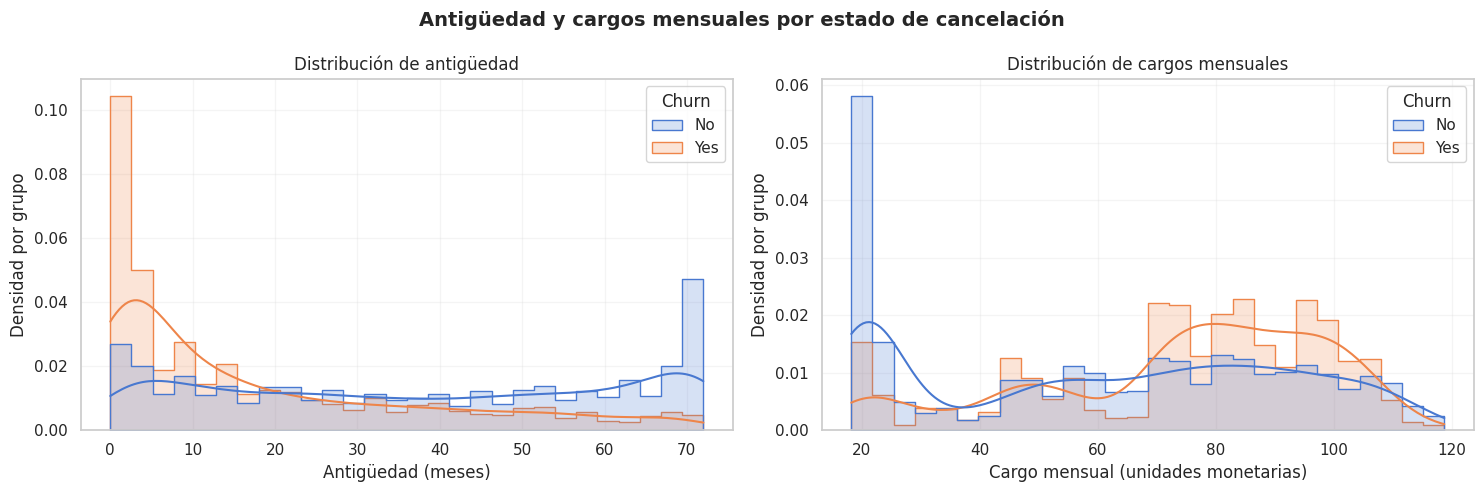

Interpretación: la distribución de los clientes que cancelaron se concentra en antigüedades menores y presenta cargos mensuales generalmente más altos. Estas distribuciones no muestran por sí mismas las tasas de cancelación por categoría.


In [11]:
# =============================================================================
# B.5.1 - HISTOGRAMAS / KDE SEGÚN CHURN
# =============================================================================
fig, ejes_b = plt.subplots(1, 2, figsize=(15, 5))
config_hist_b = [
    ('TenureMonths', 'Antigüedad (meses)', 'Distribución de antigüedad'),
    ('MonthlyCharges', 'Cargo mensual (unidades monetarias)', 'Distribución de cargos mensuales')
]
for eje_b, (variable_b, xlabel_b, titulo_b) in zip(ejes_b, config_hist_b):
    sns.histplot(
        data=df_b, x=variable_b, hue='Churn', hue_order=['No', 'Yes'],
        bins=28, kde=True, stat='density', common_norm=False,
        element='step', alpha=0.22, ax=eje_b
    )
    eje_b.set(title=titulo_b, xlabel=xlabel_b, ylabel='Densidad por grupo')
    eje_b.grid(alpha=0.2)
fig.suptitle('Antigüedad y cargos mensuales por estado de cancelación', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

print(
    'Interpretación: la distribución de los clientes que cancelaron se concentra '
    'en antigüedades menores y presenta cargos mensuales generalmente más altos. '
    'Estas distribuciones no muestran por sí mismas las tasas de cancelación por categoría.'
)

### B.5.2 Mapa de calor de correlación

El *heatmap* permite identificar visualmente qué variables monetarias están más asociadas entre sí y con la antigüedad. La escala va de -1 (asociación negativa) a +1 (positiva).

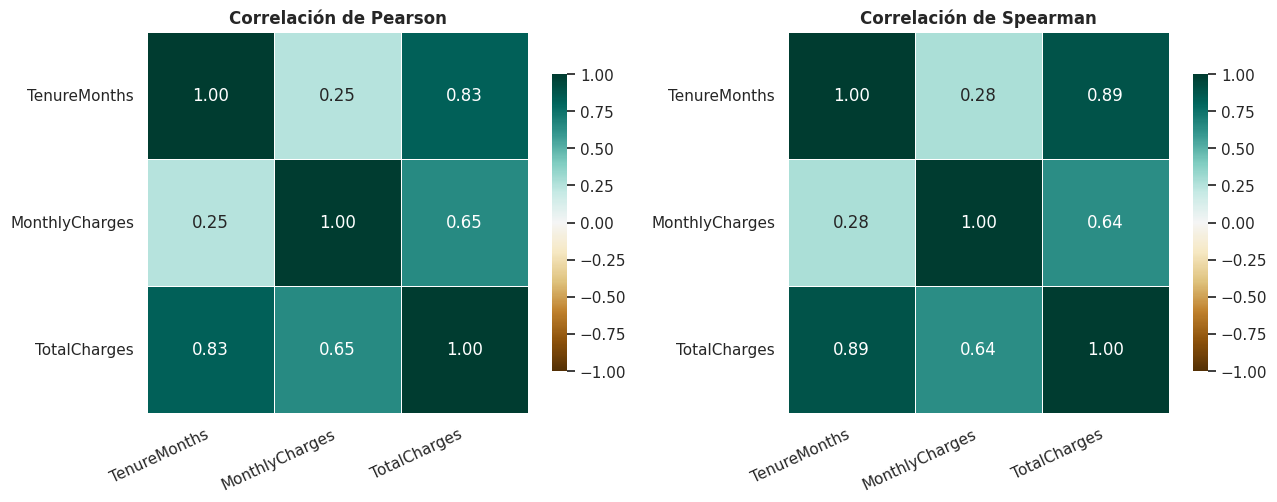

In [12]:
# =============================================================================
# B.5.2 - HEATMAP DE PEARSON Y SPEARMAN
# =============================================================================
fig, ejes_b = plt.subplots(1, 2, figsize=(13, 5))
for eje_b, matriz_b, metodo_b in zip(
    ejes_b,
    [correlacion_pearson_b, correlacion_spearman_b],
    ['Pearson', 'Spearman']
):
    sns.heatmap(
        matriz_b, annot=True, fmt='.2f', cmap='BrBG',
        vmin=-1, vmax=1, center=0, square=True, linewidths=0.6,
        cbar_kws={'shrink': 0.78}, ax=eje_b
    )
    eje_b.set_title(f'Correlación de {metodo_b}', weight='bold')
    eje_b.set_xticklabels(eje_b.get_xticklabels(), rotation=25, ha='right')
    eje_b.set_yticklabels(eje_b.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

### B.5.3 Barras comparativas: cancelación por contrato y forma de pago

Se grafica la **tasa de cancelación** (no el conteo bruto) por `Contract` y `PaymentMethod`. Cada barra incluye el número de clientes en el grupo (`n`); la línea discontinua representa la tasa general y facilita la lectura del riesgo relativo.

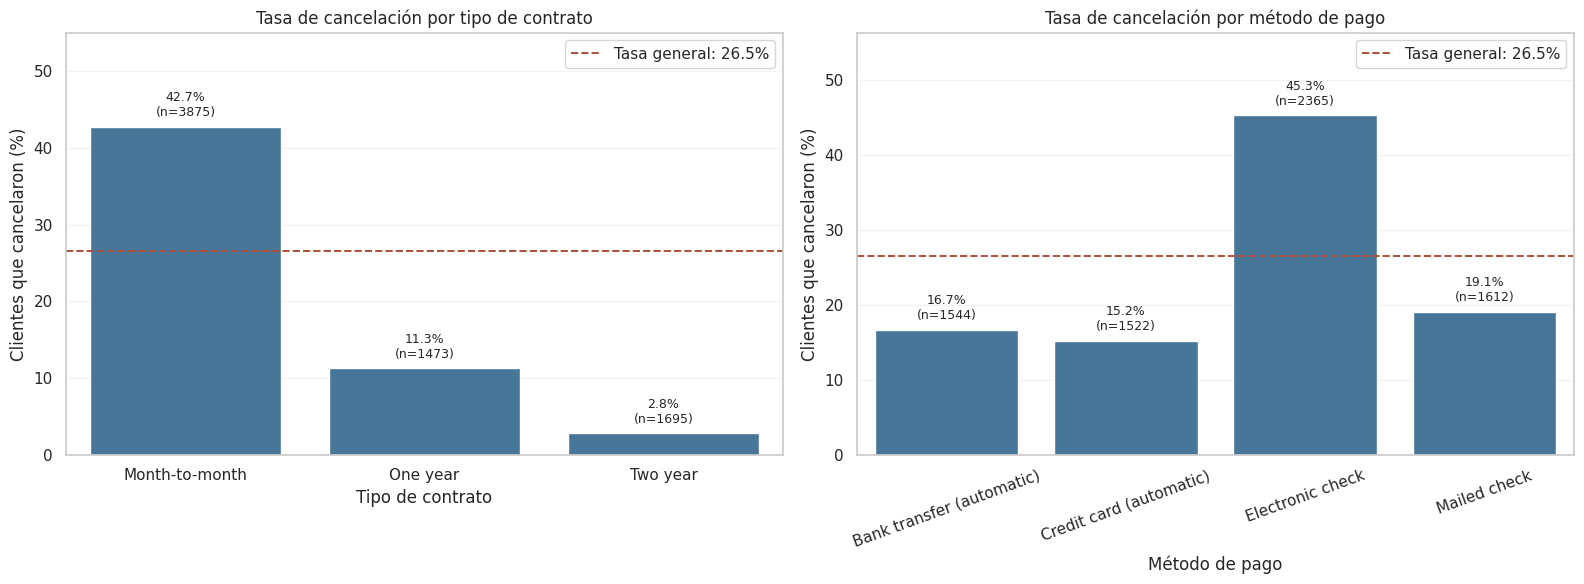

Tasas de cancelación por tipo de contrato:


,Variable,Categoría,Sin cancelación,Con cancelación,Total,Tasa Churn (%)
11,Contract,Month-to-month,2220,1655,3875,42.71
12,Contract,One year,1307,166,1473,11.27
13,Contract,Two year,1647,48,1695,2.83


Tasas de cancelación por método de pago:


,Variable,Categoría,Sin cancelación,Con cancelación,Total,Tasa Churn (%)
14,PaymentMethod,Bank transfer (automatic),1286,258,1544,16.71
15,PaymentMethod,Credit card (automatic),1290,232,1522,15.24
16,PaymentMethod,Electronic check,1294,1071,2365,45.29
17,PaymentMethod,Mailed check,1304,308,1612,19.11


In [13]:
# =============================================================================
# B.5.3 - CHURN POR TIPO DE CONTRATO Y MÉTODO DE PAGO
# =============================================================================
fig, ejes_b = plt.subplots(1, 2, figsize=(16, 6))
for eje_b, variable_b, titulo_b in zip(
    ejes_b,
    ['Contract', 'PaymentMethod'],
    ['Tipo de contrato', 'Método de pago']
):
    tasas_b = (
        df_b.groupby(variable_b, observed=True)['Churn_Binary']
        .agg(n='size', tasa='mean').reset_index()
    )
    tasas_b['tasa'] *= 100
    sns.barplot(data=tasas_b, x=variable_b, y='tasa', color='#3978a6', ax=eje_b)
    eje_b.axhline(tasa_global_b, ls='--', lw=1.4, color='#af4e35',
                   label=f'Tasa general: {tasa_global_b:.1f}%')
    eje_b.set(
        title=f'Tasa de cancelación por {titulo_b.lower()}',
        xlabel=titulo_b, ylabel='Clientes que cancelaron (%)',
        ylim=(0, max(55, tasas_b['tasa'].max() + 11))
    )
    eje_b.tick_params(axis='x', labelrotation=20 if variable_b == 'PaymentMethod' else 0)
    for i_b, fila_b in tasas_b.reset_index(drop=True).iterrows():
        eje_b.text(i_b, fila_b['tasa'] + 1, f"{fila_b['tasa']:.1f}%\n(n={int(fila_b['n'])})",
                   ha='center', va='bottom', fontsize=9)
    eje_b.legend(loc='upper right', frameon=True)
    eje_b.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print('Tasas de cancelación por tipo de contrato:')
display(contingencias_b.loc[contingencias_b['Variable'] == 'Contract'].round(2))
print('Tasas de cancelación por método de pago:')
display(contingencias_b.loc[contingencias_b['Variable'] == 'PaymentMethod'].round(2))

### B.5.4 Integración de variables: contrato × servicio de internet

El cruce de dos atributos permite revisar si la asociación con `Churn` es uniforme entre segmentos. El mapa muestra las tasas de cancelación y la tabla adjunta indica los tamaños muestrales, necesarios para interpretar cada celda con prudencia.

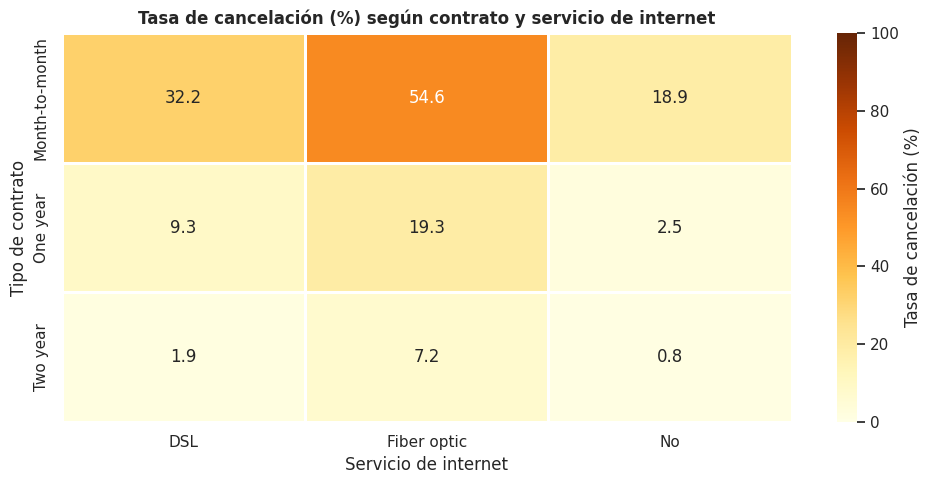

Cantidad de clientes en cada cruce:


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


In [14]:
# =============================================================================
# B.5.4 - MATRIZ DE CHURN: CONTRATO Y SERVICIO DE INTERNET
# =============================================================================
segmentos_cruzados_b = df_b.groupby(
    ['Contract', 'InternetService'], observed=True
)['Churn_Binary'].agg(n='size', tasa='mean').reset_index()
segmentos_cruzados_b['tasa'] *= 100
matriz_tasas_b = segmentos_cruzados_b.pivot(
    index='Contract', columns='InternetService', values='tasa'
)
matriz_n_b = segmentos_cruzados_b.pivot(
    index='Contract', columns='InternetService', values='n'
)

plt.figure(figsize=(10, 5))
sns.heatmap(matriz_tasas_b, annot=True, fmt='.1f', cmap='YlOrBr',
            vmin=0, vmax=100, linewidths=0.8,
            cbar_kws={'label': 'Tasa de cancelación (%)'})
plt.title('Tasa de cancelación (%) según contrato y servicio de internet', weight='bold')
plt.xlabel('Servicio de internet')
plt.ylabel('Tipo de contrato')
plt.tight_layout()
plt.show()
print('Cantidad de clientes en cada cruce:')
display(matriz_n_b)

## B.6 Hallazgos e implicancias para el negocio

1. **Cancelación total:** 1.869 de 7.043 clientes cancelaron, equivalente a **26,54 %**.
2. **Contratos:** los contratos **mes a mes** registran **42,71 %** de cancelación, frente a **11,27 %** en los anuales y **2,83 %** en los de dos años. Es razonable evaluar estrategias de fidelización y migración voluntaria a planes de mayor permanencia.
3. **Medios de pago:** **Electronic check** presenta **45,29 %** de cancelación, comparado con **15,24 %** en tarjeta de crédito automática y **16,71 %** en transferencia bancaria automática. Conviene investigar por qué sucede antes de atribuirlo al medio de pago.
4. **Antigüedad y cargos:** quienes cancelaron muestran **17,98 meses** de antigüedad media y un cargo mensual medio de **74,44**; quienes permanecieron, **37,57 meses** y **61,27**, respectivamente. La retención temprana merece un análisis específico.
5. **Segmentación conjunta:** en clientes con **contrato mes a mes y fibra óptica** la tasa observada es aproximadamente **54,6 %**. Este segmento podría priorizarse para acciones de retención, siempre validando el tamaño del grupo y la rentabilidad de las acciones.
6. **Correlación:** `TenureMonths` y `TotalCharges` presentan una asociación alta (Pearson **0,826**; Spearman **0,890**), consistente con el carácter acumulado de la facturación.

**Alcance:** se trata de un análisis descriptivo de una base de clientes; estas asociaciones no prueban que cambiar el contrato, el método de pago o el precio reduzca por sí solo la cancelación. Los modelos predictivos de la sección C podrán utilizar este análisis como insumo, evitando utilizar información derivada de la variable objetivo al predecirla.

---

# C. Preprocesamiento y Modelado Predictivo

**Pregunta analítica:** ¿cómo se preparan los datos para que un modelo aprenda de ellos sin "ver" a los clientes con los que después se lo evalúa? ¿Y cuánto de la facturación acumulada de un cliente (`TotalCharges`) puede estimarse conociendo solo su antigüedad?

Se parte del DataFrame `df` depurado en la sección A (**7.043 clientes, sin valores nulos**) y se trabaja sobre una copia (`df_modelo`), de modo que las secciones anteriores no se modifican. Aquí se desarrollan:

- **C.1 Preprocesamiento para modelado:** selección de predictoras, partición estratificada 80/20, codificación de las variables categóricas (ordinal y *One-Hot*) y estandarización de las cuantitativas.
- **C.2 Predicción numérica:** regresión lineal simple para estimar `TotalCharges` a partir de `TenureMonths`, evaluada con R² y MAE.

La predicción categórica de `Churn` (clasificación) continúa a partir de los conjuntos que quedan preparados en C.1.

> **Criterio rector — prevención de *data leakage*:** todo lo que se aprende de los datos (medias y desvíos del escalado, categorías de los codificadores, coeficientes del modelo) se calcula **únicamente con el conjunto de entrenamiento**. El conjunto de prueba se reserva para medir el desempeño sobre clientes que el modelo no vio.

## C.0 Preparación: librerías, semilla y base de trabajo

Se importan las herramientas de *scikit-learn*, se fija la semilla aleatoria y se crea la copia de trabajo `df_modelo`. No se vuelve a cargar ni a limpiar el dataset: se reutiliza el resultado de la sección A.

In [15]:
# =============================================================================
# C.0 - LIBRERÍAS DE MODELADO, SEMILLA Y BASE DE TRABAJO
# =============================================================================
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

SEMILLA = 42              # semilla fija: la partición es idéntica en cada ejecución
PROPORCION_PRUEBA = 0.20  # 80 % entrenamiento / 20 % prueba

df_modelo = df.copy(deep=True)

print(f'Clientes disponibles para modelar: {len(df_modelo):,}'.replace(',', '.'))
print(f'Columnas heredadas de la sección A: {df_modelo.shape[1]}')
print(f'Valores nulos: {int(df_modelo.isna().sum().sum())}')
print(f'Semilla aleatoria: {SEMILLA} | Proporción de prueba: {PROPORCION_PRUEBA:.0%}')

Clientes disponibles para modelar: 7.043
Columnas heredadas de la sección A: 24
Valores nulos: 0
Semilla aleatoria: 42 | Proporción de prueba: 20%


## C.1 Preprocesamiento de datos para modelado — Kevin

Los algoritmos de *scikit-learn* trabajan con matrices numéricas: no aceptan texto, y varios de ellos (como la regresión logística) son sensibles a la escala de las variables. El preprocesamiento convierte el DataFrame depurado en esa matriz en cuatro pasos:

| Paso | Qué se hace | Herramienta |
| :---: | --- | --- |
| 1 | Elegir las predictoras y unificar categorías redundantes | Pandas |
| 2 | Separar entrenamiento y prueba (80/20, estratificado por `Churn`) | `train_test_split` |
| 3 | Codificar las variables categóricas | `OrdinalEncoder` y `OneHotEncoder` |
| 4 | Estandarizar las variables cuantitativas | `StandardScaler` |

El orden importa: **primero se particiona y recién después se ajustan** los codificadores y el escalador (pasos 3 y 4), usando solo el conjunto de entrenamiento.

### C.1.1 Selección de predictoras y categorías redundantes

De las 24 columnas del DataFrame se seleccionan **18 predictoras**: 2 cuantitativas, 1 cualitativa ordinal y 15 cualitativas nominales, según el relevamiento de la sección A. No se usan como predictoras:

- **`Churn` y `Churn_Binary`:** son la variable objetivo de la clasificación.
- **`TotalCharges`:** es la variable objetivo de la regresión (C.2) y, además, equivale casi exactamente a antigüedad × cargo mensual, dos predictoras que ya están incluidas (sección B: Pearson 0,83 con `TenureMonths`). Sumarla solo agregaría multicolinealidad.
- **`TheoreticalTotalCharges`, `BillingVariance` y `AvgHistoricalMonthlyCharge`:** se calcularon en la sección A a partir de las columnas anteriores; no aportan información nueva.

**Categorías redundantes.** Seis servicios adicionales incluyen la categoría `No internet service`, y `MultipleLines` incluye `No phone service`. Esa información ya está en `InternetService` y `PhoneService`: si se codificaran así, se generarían columnas duplicadas. Antes de unificarlas como `No` se comprueba, fila por fila, que la equivalencia sea exacta. Es una recodificación fija —no aprende ningún parámetro de los datos—, por lo que puede hacerse antes de la partición sin riesgo de *leakage*.

In [16]:
# =============================================================================
# C.1.1 - SELECCIÓN DE PREDICTORAS Y CATEGORÍAS REDUNDANTES
# =============================================================================
variables_numericas_c = ['TenureMonths', 'MonthlyCharges']
variables_ordinales_c = ['Contract']
variables_nominales_c = [
    'gender', 'IsSeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'PaperlessBilling', 'PaymentMethod'
]
predictoras_c = variables_numericas_c + variables_ordinales_c + variables_nominales_c
objetivo_clasificacion = 'Churn_Binary'   # 1 = canceló, 0 = permanece (creada en la sección A)
objetivo_regresion = 'TotalCharges'       # monto total facturado al cliente

columnas_necesarias_c = predictoras_c + [objetivo_clasificacion, objetivo_regresion]
faltantes_c = sorted(set(columnas_necesarias_c).difference(df.columns))
if faltantes_c:
    raise KeyError(f'Faltan columnas de la sección A: {faltantes_c}')

# --- Categorías redundantes: se comprueba la equivalencia y luego se unifican ---
servicios_internet_c = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                        'TechSupport', 'StreamingTV', 'StreamingMovies']

print('Evidencia: "No internet service" solo aparece en los clientes sin servicio de internet')
display(pd.crosstab(df['InternetService'], df['OnlineSecurity']))

for col in servicios_internet_c:
    assert ((df[col] == 'No internet service') == (df['InternetService'] == 'No')).all(), col
    df_modelo[col] = df[col].astype(str).replace('No internet service', 'No')

assert ((df['MultipleLines'] == 'No phone service') == (df['PhoneService'] == 'No')).all()
df_modelo['MultipleLines'] = df['MultipleLines'].astype(str).replace('No phone service', 'No')

# --- Rol de cada columna en el modelado ---
motivos_exclusion_c = {
    'TotalCharges': 'Objetivo de la regresión (C.2); redundante con antigüedad × cargo mensual',
    'TheoreticalTotalCharges': 'Calculada: TenureMonths × MonthlyCharges (ya incluidas)',
    'BillingVariance': 'Calculada a partir de TotalCharges',
    'AvgHistoricalMonthlyCharge': 'Calculada a partir de TotalCharges; casi idéntica a MonthlyCharges',
    'Churn': 'Objetivo en texto; se usa su versión 0/1 (Churn_Binary)',
    'Churn_Binary': 'Variable objetivo de la clasificación'
}
filas_roles_c = []
for col in df_modelo.columns:
    if col in variables_numericas_c:
        rol_c, tratamiento_c = 'Predictora cuantitativa', 'Estandarización (StandardScaler)'
    elif col in variables_ordinales_c:
        rol_c, tratamiento_c = 'Predictora cualitativa ordinal', 'Codificación ordinal (OrdinalEncoder)'
    elif col in variables_nominales_c:
        rol_c, tratamiento_c = 'Predictora cualitativa nominal', 'One-Hot Encoding (OneHotEncoder)'
    else:
        rol_c = 'No se usa como predictora'
        tratamiento_c = motivos_exclusion_c.get(col, 'Columna auxiliar de secciones anteriores')
    filas_roles_c.append({
        'Columna': col,
        'Valores distintos': df_modelo[col].nunique(),
        'Rol en el modelado': rol_c,
        'Tratamiento / motivo': tratamiento_c
    })
roles_c = pd.DataFrame(filas_roles_c)

print('\nRol de cada columna (los servicios ya figuran con dos categorías: No / Yes):')
with pd.option_context('display.max_colwidth', None):
    display(roles_c)

print(
    f'Predictoras seleccionadas: {len(predictoras_c)} de {df_modelo.shape[1]} columnas '
    f'({len(variables_numericas_c)} cuantitativas, {len(variables_ordinales_c)} ordinal y '
    f'{len(variables_nominales_c)} nominales).'
)

Evidencia: "No internet service" solo aparece en los clientes sin servicio de internet


OnlineSecurity,No,No internet service,Yes
InternetService,,,
DSL,1241,0,1180
Fiber optic,2257,0,839
No,0,1526,0



Rol de cada columna (los servicios ya figuran con dos categorías: No / Yes):


,Columna,Valores distintos,Rol en el modelado,Tratamiento / motivo
0,gender,2,Predictora cualitativa nominal,One-Hot Encoding (OneHotEncoder)
1,IsSeniorCitizen,2,Predictora cualitativa nominal,One-Hot Encoding (OneHotEncoder)
2,Partner,2,Predictora cualitativa nominal,One-Hot Encoding (OneHotEncoder)
3,Dependents,2,Predictora cualitativa nominal,One-Hot Encoding (OneHotEncoder)
4,TenureMonths,73,Predictora cuantitativa,Estandarización (StandardScaler)
5,PhoneService,2,Predictora cualitativa nominal,One-Hot Encoding (OneHotEncoder)
6,MultipleLines,2,Predictora cualitativa nominal,One-Hot Encoding (OneHotEncoder)
7,InternetService,3,Predictora cualitativa nominal,One-Hot Encoding (OneHotEncoder)
8,OnlineSecurity,2,Predictora cualitativa nominal,One-Hot Encoding (OneHotEncoder)
9,OnlineBackup,2,Predictora cualitativa nominal,One-Hot Encoding (OneHotEncoder)


Predictoras seleccionadas: 18 de 24 columnas (2 cuantitativas, 1 ordinal y 15 nominales).


### C.1.2 Partición estratificada 80/20

Se separa el **20 % de los clientes como conjunto de prueba** antes de cualquier ajuste. Ese conjunto simula clientes "nuevos": no interviene en el cálculo del escalado, de la codificación ni de los coeficientes de los modelos.

- **`stratify=y`:** `Churn` está desbalanceada (26,5 % de cancelaciones). La estratificación garantiza la misma proporción en ambos conjuntos; sin ella, la tasa del conjunto de prueba dependería del azar del sorteo.
- **`random_state=SEMILLA`:** fija el sorteo para que la partición —y, por lo tanto, todas las métricas— se repita en cada ejecución.
- **Una sola partición para toda la sección C:** la regresión y la clasificación se entrenan y se evalúan con los mismos clientes.

In [17]:
# =============================================================================
# C.1.2 - PARTICIÓN ESTRATIFICADA EN ENTRENAMIENTO (80 %) Y PRUEBA (20 %)
# =============================================================================
X = df_modelo[predictoras_c]
y = df_modelo[objetivo_clasificacion]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=PROPORCION_PRUEBA,   # 20 % de los clientes para evaluar
    stratify=y,                    # misma proporción de Churn en ambos conjuntos
    random_state=SEMILLA           # sorteo reproducible
)

resumen_particion_c = pd.DataFrame({
    'Clientes': [len(y), len(y_train), len(y_test)],
    'Proporción de la base (%)': [100.0, 100 * len(y_train) / len(y), 100 * len(y_test) / len(y)],
    'Cancelaron': [int(y.sum()), int(y_train.sum()), int(y_test.sum())],
    'Tasa de Churn (%)': [100 * y.mean(), 100 * y_train.mean(), 100 * y_test.mean()]
}, index=['Base completa', 'Entrenamiento', 'Prueba'])
display(resumen_particion_c.round(2))

# Ningún cliente puede estar en los dos conjuntos, y entre ambos deben sumar la base completa
assert X_train.index.intersection(X_test.index).empty
assert len(X_train) + len(X_test) == len(df_modelo)

# ¿Qué pasaría sin estratificar? Se repite el sorteo con 200 semillas distintas
tasas_sin_estratificar_c = [
    100 * train_test_split(y, test_size=PROPORCION_PRUEBA, random_state=semilla)[1].mean()
    for semilla in range(200)
]
print(
    f'Sin estratificar, en 200 sorteos la tasa de Churn del conjunto de prueba varía entre '
    f'{min(tasas_sin_estratificar_c):.1f} % y {max(tasas_sin_estratificar_c):.1f} %.'
)
print(f'Con stratify=y queda fija en {100 * y_test.mean():.2f} %, igual a la de la base completa.')

,Clientes,Proporción de la base (%),Cancelaron,Tasa de Churn (%)
Base completa,7043,100.00,1869,26.54
Entrenamiento,5634,79.99,1495,26.54
Prueba,1409,20.01,374,26.54


Sin estratificar, en 200 sorteos la tasa de Churn del conjunto de prueba varía entre 23.2 % y 30.2 %.
Con stratify=y queda fija en 26.54 %, igual a la de la base completa.


### C.1.3 Codificación y estandarización (ajustadas solo con entrenamiento)

| Grupo | Variables | Transformación | Justificación |
| --- | --- | --- | --- |
| Cuantitativas | `TenureMonths`, `MonthlyCharges` | `StandardScaler`: (valor − media) / desvío | Están en unidades distintas (meses y dinero). Con media 0 y desvío 1 ninguna pesa más solo por su escala y sus coeficientes se vuelven comparables. Se prefiere a `MinMaxScaler` porque centra las variables en 0 —lo que esperan los modelos lineales con regularización— y no depende únicamente del mínimo y del máximo observados. |
| Ordinal | `Contract` | `OrdinalEncoder` con orden explícito: mes a mes = 0, un año = 1, dos años = 2 | Las categorías tienen un orden natural (el plazo de compromiso), el mismo que se definió en la sección A. Una sola columna conserva ese orden; asume escalones equidistantes, una simplificación habitual en variables ordinales. |
| Nominales | Las 15 restantes | `OneHotEncoder(drop='first')`: una columna 0/1 por categoría, omitiendo la primera | No tienen orden: asignarles 0, 1, 2… inventaría una jerarquía que no existe. Se omite una categoría por variable, que queda como **referencia**, para evitar la redundancia perfecta entre columnas (*dummy variable trap*). |

La variable objetivo `Churn` ya se codificó en la sección A como `Churn_Binary` (Yes → 1, No → 0), lo que equivale a un *Label Encoding* de la clase.

Las tres transformaciones se agrupan en un `ColumnTransformer`, que aplica a cada grupo de columnas la suya y devuelve una única tabla. Se llama a **`fit_transform` solo con `X_train`**; a `X_test` se le aplica únicamente `transform`: se lo convierte con las medias, los desvíos y las categorías aprendidos en entrenamiento.

In [18]:
# =============================================================================
# C.1.3 - CODIFICACIÓN Y ESTANDARIZACIÓN (AJUSTE SOLO CON ENTRENAMIENTO)
# =============================================================================
orden_contrato_c = ['Month-to-month', 'One year', 'Two year']   # de menor a mayor plazo de compromiso

preprocesador = ColumnTransformer(
    transformers=[
        ('cuantitativas', StandardScaler(), variables_numericas_c),
        ('ordinal', OrdinalEncoder(categories=[orden_contrato_c], dtype=int), variables_ordinales_c),
        ('nominales', OneHotEncoder(drop='first', sparse_output=False, dtype=int), variables_nominales_c)
    ],
    verbose_feature_names_out=False   # nombres legibles: 'Contract', 'gender_Male', ...
)
preprocesador.set_output(transform='pandas')   # devuelve DataFrames con nombres de columna

X_train_prep = preprocesador.fit_transform(X_train)   # aprende y transforma: SOLO entrenamiento
X_test_prep = preprocesador.transform(X_test)         # solo transforma, con lo aprendido arriba

# Qué categoría quedó como referencia en cada variable nominal y qué columnas se generaron
codificador_nominal_c = preprocesador.named_transformers_['nominales']
filas_referencias_c = []
for variable_c, categorias_c, omitida_c in zip(
    variables_nominales_c, codificador_nominal_c.categories_, codificador_nominal_c.drop_idx_
):
    filas_referencias_c.append({
        'Variable nominal': variable_c,
        'Categoría de referencia (omitida)': categorias_c[omitida_c],
        'Columnas generadas': ', '.join(
            f'{variable_c}_{categoria_c}' for categoria_c in categorias_c if categoria_c != categorias_c[omitida_c]
        )
    })
print('Codificación One-Hot: categoría de referencia y columnas resultantes')
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(filas_referencias_c))

print('Primeras filas del conjunto de entrenamiento ya transformado:')
display(X_train_prep.head(3))

print(
    f'Predictoras originales: {X_train.shape[1]} → columnas del modelo: {X_train_prep.shape[1]} '
    f'({len(variables_numericas_c)} estandarizadas, {len(variables_ordinales_c)} ordinal y '
    f'{X_train_prep.shape[1] - len(variables_numericas_c) - len(variables_ordinales_c)} indicadoras 0/1).'
)
print(f'Entrenamiento: {X_train_prep.shape[0]} filas | Prueba: {X_test_prep.shape[0]} filas')

Codificación One-Hot: categoría de referencia y columnas resultantes


,Variable nominal,Categoría de referencia (omitida),Columnas generadas
0,gender,Female,gender_Male
1,IsSeniorCitizen,No,IsSeniorCitizen_Yes
2,Partner,No,Partner_Yes
3,Dependents,No,Dependents_Yes
4,PhoneService,No,PhoneService_Yes
5,MultipleLines,No,MultipleLines_Yes
6,InternetService,DSL,"InternetService_Fiber optic, InternetService_No"
7,OnlineSecurity,No,OnlineSecurity_Yes
8,OnlineBackup,No,OnlineBackup_Yes
9,DeviceProtection,No,DeviceProtection_Yes


Primeras filas del conjunto de entrenamiento ya transformado:


,TenureMonths,MonthlyCharges,Contract,gender_Male,IsSeniorCitizen_Yes,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
3738,0.10,-0.52,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,1,0
3151,-0.71,0.34,0,1,0,1,1,1,0,1,0,1,0,0,0,0,0,0,0,0,1
4860,-0.79,-0.81,2,1,0,1,1,0,0,0,0,1,1,0,1,0,0,0,0,0,1


Predictoras originales: 18 → columnas del modelo: 21 (2 estandarizadas, 1 ordinal y 18 indicadoras 0/1).
Entrenamiento: 5634 filas | Prueba: 1409 filas


### C.1.4 Control de fuga de información

Si el escalador se hubiera ajustado con toda la base, sus medias y desvíos incluirían a los clientes de prueba y la evaluación quedaría contaminada. Para comprobar que no ocurrió se comparan las variables estandarizadas en ambos conjuntos: en entrenamiento la media debe ser exactamente 0 y el desvío 1; en prueba deben ser **cercanos, pero no exactos**, porque esos clientes no participaron del ajuste.

In [19]:
# =============================================================================
# C.1.4 - CONTROL DE FUGA DE INFORMACIÓN Y VERIFICACIONES FINALES
# =============================================================================
escalador_c = preprocesador.named_transformers_['cuantitativas']

control_escalado_c = pd.DataFrame({
    'Media aprendida (entrenamiento)': escalador_c.mean_,
    'Desvío aprendido (entrenamiento)': escalador_c.scale_,
    'Media escalada: entrenamiento': X_train_prep[variables_numericas_c].mean().values,
    'Desvío escalado: entrenamiento': X_train_prep[variables_numericas_c].std(ddof=0).values,
    'Media escalada: prueba': X_test_prep[variables_numericas_c].mean().values,
    'Desvío escalado: prueba': X_test_prep[variables_numericas_c].std(ddof=0).values
}, index=variables_numericas_c)

with pd.option_context('display.float_format', '{:.3f}'.format):
    display(control_escalado_c.round(3) + 0.0)   # "+ 0.0" evita que un cero se muestre como -0.000

# Controles: si alguno falla, la ejecución se detiene en lugar de seguir con datos mal preparados
assert np.allclose(X_train_prep[variables_numericas_c].mean(), 0, atol=1e-9)
assert np.allclose(X_train_prep[variables_numericas_c].std(ddof=0), 1, atol=1e-9)
assert list(X_train_prep.columns) == list(X_test_prep.columns)
assert not X_train_prep.isna().any().any() and not X_test_prep.isna().any().any()
assert X_train_prep.index.equals(X_train.index) and X_test_prep.index.equals(X_test.index)

print('Controles superados:')
print(' - En entrenamiento, las variables estandarizadas tienen media 0 y desvío 1.')
print(' - En prueba no son exactamente 0 y 1: el escalador no "vio" a esos clientes.')
print(' - Entrenamiento y prueba tienen las mismas columnas, en el mismo orden y sin valores nulos.')

,Media aprendida (entrenamiento),Desvío aprendido (entrenamiento),Media escalada: entrenamiento,Desvío escalado: entrenamiento,Media escalada: prueba,Desvío escalado: prueba
TenureMonths,32.485,24.567,0.000,1.000,-0.023,0.998
MonthlyCharges,64.930,30.135,0.000,1.000,-0.028,0.992


Controles superados:
 - En entrenamiento, las variables estandarizadas tienen media 0 y desvío 1.
 - En prueba no son exactamente 0 y 1: el escalador no "vio" a esos clientes.
 - Entrenamiento y prueba tienen las mismas columnas, en el mismo orden y sin valores nulos.


**Resultado de C.1.** Las 18 predictoras se convierten en **21 columnas numéricas** (2 estandarizadas, 1 ordinal y 18 indicadoras 0/1), con 5.634 clientes para entrenar y 1.409 para evaluar, ambos con 26,54 % de cancelaciones. Quedan disponibles para el modelado:

| Objeto | Contenido |
| --- | --- |
| `X_train`, `X_test` | Predictoras originales, sin transformar, de cada conjunto |
| `X_train_prep`, `X_test_prep` | Predictoras codificadas y estandarizadas (21 columnas) |
| `y_train`, `y_test` | Variable objetivo de la clasificación (`Churn_Binary`) |
| `preprocesador` | `ColumnTransformer` ajustado con entrenamiento; puede reutilizarse dentro de un `Pipeline` |

### C.1.5 Exportación de los datasets procesados

Los resultados del procesamiento se guardan en `data/processed/`, separados de los datos originales de `data/raw/`, que nunca se modifican. Al ejecutar el notebook, los archivos se regeneran:

| Archivo | Contenido |
| --- | --- |
| `telco_churn_procesado.csv` | Dataset **depurado**: salida de la sección A (tipos corregidos, sin nulos y con las columnas calculadas) |
| `telco_churn_modelado.csv` | Dataset **transformado**: las 21 columnas codificadas y estandarizadas, la variable objetivo y el conjunto (`entrenamiento` / `prueba`) de cada cliente |

En ambos se recupera `customerID` del archivo original únicamente como clave de **trazabilidad**: permite volver de cualquier fila procesada al registro crudo, pero no se usa como predictora.

In [20]:
# =============================================================================
# C.1.5 - EXPORTACIÓN DE LOS DATASETS PROCESADOS (data/processed/)
# =============================================================================
# Dentro del repositorio se escribe en ../data/processed; en Colab, en data/processed
DIR_PROCESADOS = '../data/processed' if os.path.isdir('../data/raw') else 'data/processed'
os.makedirs(DIR_PROCESADOS, exist_ok=True)

# El identificador se toma del CSV original: las filas conservan el mismo orden
assert df.index.equals(df_raw.index), 'El orden de las filas cambió respecto del CSV original'
identificadores_c = df_raw['customerID']

# 1) Dataset depurado (sección A)
export_procesado = df.copy()
if 'customerID' not in export_procesado.columns:
    export_procesado.insert(0, 'customerID', identificadores_c)

# 2) Dataset transformado (C.1): matriz de modelado + partición + variable objetivo
export_modelado = pd.concat([X_train_prep, X_test_prep]).sort_index()
export_modelado.insert(0, 'customerID', identificadores_c)
export_modelado.insert(1, 'conjunto', np.where(export_modelado.index.isin(X_train.index), 'entrenamiento', 'prueba'))
export_modelado[objetivo_clasificacion] = y

archivos_c = {
    'telco_churn_procesado.csv': export_procesado.round(4),
    'telco_churn_modelado.csv': export_modelado.round(6)
}
print('Archivos generados:')
for nombre_c, tabla_c in archivos_c.items():
    tabla_c.to_csv(f'{DIR_PROCESADOS}/{nombre_c}', index=False, lineterminator='\n')
    print(f' - {DIR_PROCESADOS}/{nombre_c}: {tabla_c.shape[0]} filas × {tabla_c.shape[1]} columnas')

Archivos generados:


 - ../data/processed/telco_churn_procesado.csv: 7043 filas × 25 columnas


 - ../data/processed/telco_churn_modelado.csv: 7043 filas × 24 columnas


## C.2 Predicción numérica: regresión lineal simple — Kevin

**Objetivo:** estimar `TotalCharges` —variable cuantitativa continua: el monto total facturado a cada cliente— a partir de **una única variable explicativa**, con el modelo

$$\widehat{\text{TotalCharges}} = \beta_0 + \beta_1 \cdot \text{TenureMonths}$$

**¿Por qué `TenureMonths`?** Es la variable más correlacionada con `TotalCharges` (sección B: Pearson 0,83 y Spearman 0,89, frente a 0,65 de `MonthlyCharges`) y la relación tiene sentido de negocio: la facturación se acumula mes a mes.

**Decisiones metodológicas**

- **Misma partición que en C.1:** el modelo se ajusta con los 5.634 clientes de entrenamiento y se evalúa con los 1.409 de prueba.
- **Sin *leakage* por construcción:** no se usan `BillingVariance` ni `AvgHistoricalMonthlyCharge`, que se calculan a partir del propio `TotalCharges`; tampoco `TheoreticalTotalCharges` (antigüedad × cargo mensual), que reproduce casi exactamente el objetivo (r ≈ 1,00) y volvería trivial el ejercicio.
- **Predictora sin estandarizar:** en una regresión lineal simple el escalado no cambia las predicciones ni el R²; solo cambia las unidades de la pendiente. En meses, la pendiente se lee directamente como dinero por mes de permanencia (se comprueba al final de la celda).
- **Línea base:** las métricas se comparan con un modelo que predice siempre la media de entrenamiento, para medir cuánto aporta realmente la antigüedad.

Los montos se interpretan en dólares (USD), la moneda de la empresa del dataset de muestra de IBM.

### C.2.1 Entrenamiento y evaluación (R² y MAE)

In [21]:
# =============================================================================
# C.2.1 - REGRESIÓN LINEAL SIMPLE: TotalCharges ~ TenureMonths
# =============================================================================
predictora_reg = ['TenureMonths']

# Misma partición estratificada de C.1: mismos clientes en entrenamiento y en prueba
X_train_reg = X_train[predictora_reg]
X_test_reg = X_test[predictora_reg]
y_train_reg = df_modelo.loc[X_train.index, objetivo_regresion]
y_test_reg = df_modelo.loc[X_test.index, objetivo_regresion]

modelo_regresion = LinearRegression()
modelo_regresion.fit(X_train_reg, y_train_reg)   # ajuste SOLO con entrenamiento

ordenada_reg = modelo_regresion.intercept_
pendiente_reg = modelo_regresion.coef_[0]

pred_train_reg = modelo_regresion.predict(X_train_reg)
pred_test_reg = modelo_regresion.predict(X_test_reg)

# Línea base: predecir siempre la media de TotalCharges observada en entrenamiento
linea_base_reg = DummyRegressor(strategy='mean').fit(X_train_reg, y_train_reg)
pred_base_reg = linea_base_reg.predict(X_test_reg)


def metricas_regresion(y_real, y_estimado):
    """Devuelve R², MAE y RMSE de un conjunto de predicciones."""
    return {
        'R²': r2_score(y_real, y_estimado),
        'MAE (USD)': mean_absolute_error(y_real, y_estimado),
        'RMSE (USD)': np.sqrt(mean_squared_error(y_real, y_estimado))
    }


evaluacion_reg = pd.DataFrame({
    'Modelo: entrenamiento': metricas_regresion(y_train_reg, pred_train_reg),
    'Modelo: prueba': metricas_regresion(y_test_reg, pred_test_reg),
    'Línea base: prueba': metricas_regresion(y_test_reg, pred_base_reg)
}).T
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(evaluacion_reg)

r2_test_reg = evaluacion_reg.loc['Modelo: prueba', 'R²']
mae_test_reg = evaluacion_reg.loc['Modelo: prueba', 'MAE (USD)']
mae_base_reg = evaluacion_reg.loc['Línea base: prueba', 'MAE (USD)']

print(f'Recta estimada: TotalCharges = {ordenada_reg:.2f} + {pendiente_reg:.2f} × TenureMonths')
print(f'R² en prueba = {r2_test_reg:.3f}: la antigüedad explica el {r2_test_reg:.1%} de la variabilidad '
      f'de TotalCharges en clientes que el modelo no vio.')
print(f'MAE en prueba = {mae_test_reg:.2f}: en promedio, cada estimación se aleja USD {mae_test_reg:.0f} del valor real.')
print(f'Línea base (predecir siempre la media): MAE = {mae_base_reg:.2f}. '
      f'El modelo reduce el error un {1 - mae_test_reg / mae_base_reg:.1%}.')

# Comprobación: estandarizar la predictora no cambia el ajuste, solo las unidades de la pendiente
escalador_reg = StandardScaler().fit(X_train_reg)
modelo_reg_escalado = LinearRegression().fit(escalador_reg.transform(X_train_reg), y_train_reg)
r2_escalado_reg = r2_score(y_test_reg, modelo_reg_escalado.predict(escalador_reg.transform(X_test_reg)))
assert np.isclose(r2_escalado_reg, r2_test_reg)
print(f'\nCon TenureMonths estandarizada: R² en prueba = {r2_escalado_reg:.3f} (idéntico). La pendiente pasa a ser '
      f'{modelo_reg_escalado.coef_[0]:.2f} por cada desvío estándar ({escalador_reg.scale_[0]:.2f} meses) '
      f'= {pendiente_reg:.2f} × {escalador_reg.scale_[0]:.2f}.')

,R²,MAE (USD),RMSE (USD)
Modelo: entrenamiento,0.688,879.063,1272.166
Modelo: prueba,0.657,876.176,1297.171
Línea base: prueba,-0.002,1857.566,2216.921


Recta estimada: TotalCharges = -201.04 + 76.97 × TenureMonths
R² en prueba = 0.657: la antigüedad explica el 65.7% de la variabilidad de TotalCharges en clientes que el modelo no vio.
MAE en prueba = 876.18: en promedio, cada estimación se aleja USD 876 del valor real.
Línea base (predecir siempre la media): MAE = 1857.57. El modelo reduce el error un 52.8%.

Con TenureMonths estandarizada: R² en prueba = 0.657 (idéntico). La pendiente pasa a ser 1890.88 por cada desvío estándar (24.57 meses) = 76.97 × 24.57.


### C.2.2 Diagnóstico gráfico: recta estimada y residuos

Se grafican los clientes del **conjunto de prueba**. A la izquierda, los valores reales frente a la recta estimada. A la derecha, los **residuos** (valor real − valor estimado) según la antigüedad, coloreados por el cargo mensual: si el modelo fuera suficiente, los residuos formarían una banda horizontal de ancho constante alrededor de 0.

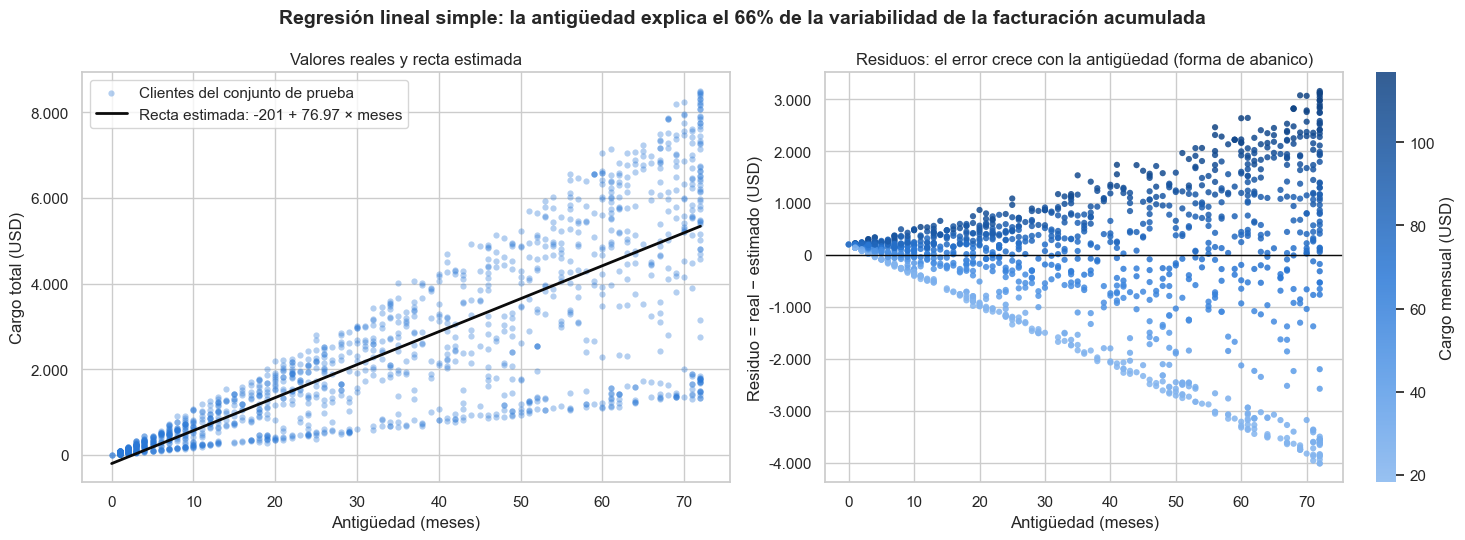

Error del modelo por tramo de antigüedad (conjunto de prueba):


,Clientes,MAE (USD),Error absoluto máximo (USD)
Antigüedad (meses),,,
0 a 12,449,180.90,537.40
13 a 24,206,453.00,1193.70
25 a 48,304,907.10,2610.20
49 o más,450,1742.70,4017.90


Correlación entre el residuo y MonthlyCharges: 0.78 (los clientes de cargo mensual alto quedan por encima de la recta).
Predicciones negativas: 180 de 1409 clientes de prueba (antigüedad menor a 2.6 meses).


In [22]:
# =============================================================================
# C.2.2 - RECTA DE REGRESIÓN Y RESIDUOS EN EL CONJUNTO DE PRUEBA
# =============================================================================
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

residuos_test_reg = y_test_reg - pred_test_reg
cargo_mensual_test_reg = df_modelo.loc[X_test.index, 'MonthlyCharges']
antiguedad_test_reg = X_test_reg['TenureMonths']

escala_azul_c = LinearSegmentedColormap.from_list(
    'escala_azul', ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281']   # un solo tono: más oscuro = cargo mayor
)
formato_miles_c = FuncFormatter(lambda valor, _: f'{valor:,.0f}'.replace(',', '.'))

fig, ejes_c = plt.subplots(1, 2, figsize=(15, 5.5))

# Izquierda: valores reales y recta estimada
eje_c = ejes_c[0]
eje_c.scatter(antiguedad_test_reg, y_test_reg, s=20, color='#2a78d6', alpha=0.35, linewidths=0,
              label='Clientes del conjunto de prueba')
x_recta_c = np.array([0, antiguedad_test_reg.max()])
eje_c.plot(x_recta_c, ordenada_reg + pendiente_reg * x_recta_c, color='#0b0b0b', lw=2,
           label=f'Recta estimada: {ordenada_reg:.0f} + {pendiente_reg:.2f} × meses')
eje_c.set(title='Valores reales y recta estimada', xlabel='Antigüedad (meses)', ylabel='Cargo total (USD)')
eje_c.yaxis.set_major_formatter(formato_miles_c)
eje_c.legend(loc='upper left', frameon=True)

# Derecha: residuos según la antigüedad, coloreados por el cargo mensual
eje_c = ejes_c[1]
puntos_c = eje_c.scatter(antiguedad_test_reg, residuos_test_reg, c=cargo_mensual_test_reg,
                         cmap=escala_azul_c, s=20, alpha=0.85, linewidths=0)
eje_c.axhline(0, color='#0b0b0b', lw=1)
eje_c.set(title='Residuos: el error crece con la antigüedad (forma de abanico)',
          xlabel='Antigüedad (meses)', ylabel='Residuo = real − estimado (USD)')
eje_c.yaxis.set_major_formatter(formato_miles_c)
barra_c = fig.colorbar(puntos_c, ax=eje_c, label='Cargo mensual (USD)')
barra_c.outline.set_visible(False)

fig.suptitle(
    f'Regresión lineal simple: la antigüedad explica el {r2_test_reg:.0%} de la variabilidad de la facturación acumulada',
    fontsize=14, weight='bold'
)
plt.tight_layout()
plt.show()

# El error no es constante: se mide por tramo de antigüedad
tramos_reg = pd.cut(antiguedad_test_reg, bins=[-1, 12, 24, 48, np.inf],
                    labels=['0 a 12', '13 a 24', '25 a 48', '49 o más'])
errores_por_tramo_reg = (
    pd.DataFrame({'Antigüedad (meses)': tramos_reg, 'error_absoluto': residuos_test_reg.abs()})
    .groupby('Antigüedad (meses)', observed=True)['error_absoluto']
    .agg(['size', 'mean', 'max'])
    .rename(columns={'size': 'Clientes', 'mean': 'MAE (USD)', 'max': 'Error absoluto máximo (USD)'})
)
print('Error del modelo por tramo de antigüedad (conjunto de prueba):')
display(errores_por_tramo_reg.round(1))

correlacion_residuo_cargo_reg = np.corrcoef(residuos_test_reg, cargo_mensual_test_reg)[0, 1]
predicciones_negativas_reg = int((pred_test_reg < 0).sum())
print(f'Correlación entre el residuo y MonthlyCharges: {correlacion_residuo_cargo_reg:.2f} '
      f'(los clientes de cargo mensual alto quedan por encima de la recta).')
print(f'Predicciones negativas: {predicciones_negativas_reg} de {len(pred_test_reg)} clientes de prueba '
      f'(antigüedad menor a {-ordenada_reg / pendiente_reg:.1f} meses).')

### C.2.3 Interpretación y alcance del modelo

**Recta estimada con el conjunto de entrenamiento:** `TotalCharges ≈ −201,04 + 76,97 × TenureMonths`

| Métrica | Entrenamiento | Prueba | Lectura |
| --- | ---: | ---: | --- |
| R² | 0,688 | 0,657 | La antigüedad explica el 65,7 % de la variabilidad de la facturación acumulada en clientes no vistos |
| MAE | USD 879 | USD 876 | Error absoluto promedio de cada estimación |
| RMSE | USD 1.272 | USD 1.297 | Mayor que el MAE: hay errores grandes, que esta métrica penaliza más |
| MAE de la línea base | — | USD 1.858 | Predecir siempre la media: el modelo reduce el error un 52,8 % |

1. **Pendiente (USD 76,97 por mes):** cada mes adicional de permanencia se asocia, en promedio, con unos USD 77 más de facturación acumulada. Retener a un cliente un año más equivale a ≈ USD 920.
2. **Ordenada al origen (−USD 201,04):** no tiene interpretación de negocio, porque un cliente recién incorporado no puede tener facturación negativa. Es el ajuste matemático de una recta a una nube con forma de abanico; por eso el modelo predice montos negativos para antigüedades menores a 2,6 meses (180 de los 1.409 clientes de prueba).
3. **Sin sobreajuste:** el R² de entrenamiento (0,688) y el de prueba (0,657) son similares y el MAE es prácticamente el mismo. Es lo esperable en un modelo con una sola pendiente.
4. **Limitación — heterocedasticidad:** el error no es constante. El MAE pasa de USD 181 en los clientes de hasta 12 meses a USD 1.743 en los de más de 48: los residuos se abren en abanico. La causa es la variable omitida: `TotalCharges` ≈ antigüedad × cargo mensual, y la recta aplica un único "precio promedio" (la pendiente) a todos los clientes. Los de cargo mensual alto quedan por encima de la recta y los de planes básicos por debajo (correlación entre el residuo y `MonthlyCharges`: 0,78).
5. **Alcance:** el modelo sirve para estimar órdenes de magnitud y para cuantificar el valor de la permanencia, no para proyectar la facturación de un cliente puntual. El paso siguiente, fuera del alcance de esta consigna, sería una regresión lineal múltiple que incorpore `MonthlyCharges`.

> **Lectura de negocio:** la permanencia es el principal motor del ingreso acumulado: cada mes que un cliente se queda vale, en promedio, unos USD 77 de facturación. Esto refuerza el hallazgo de la sección B —quienes cancelan tienen poca antigüedad— y respalda invertir en retención temprana: cada baja evitada en el primer año conserva un ingreso que, de otro modo, deja de acumularse.

---

# D. Reproducibilidad y Buenas Prácticas — Kevin

Un análisis es confiable cuando cualquier persona puede volver a ejecutarlo y llegar a los mismos resultados. Estas son las prácticas aplicadas en el proyecto:

| Práctica | Cómo se aplica |
| --- | --- |
| **Datos originales inmutables** | El CSV de `data/raw/` nunca se modifica. Todo el procesamiento ocurre en memoria y los resultados se guardan aparte, en `data/processed/`. |
| **Ejecución de punta a punta** | El notebook corre completo con *Entorno de ejecución → Ejecutar todas* en Google Colab, sin instalar paquetes ni subir archivos: si no encuentra el CSV local, lo lee desde el repositorio público. |
| **Semilla fija** | `SEMILLA = 42` en la partición de datos: los conjuntos de entrenamiento y prueba —y, con ellos, todas las métricas— son idénticos en cada ejecución. |
| **Sin fuga de información** | La partición se hace antes de ajustar el escalado, la codificación y los modelos; el conjunto de prueba solo se usa para evaluar (C.1.4). |
| **Controles automáticos** | Las verificaciones con `assert` y `raise` detienen la ejecución si los datos no tienen la forma esperada, en lugar de producir resultados erróneos en silencio. |
| **Control de versiones** | Cada sección se desarrolla en una rama propia y se integra a `main` mediante *pull request*, con mensajes de *commit* que describen qué cambió. |
| **Estructura estándar** | `data/raw/`, `data/processed/`, `notebooks/`, `docs/` y `README.md`, según la consigna. El `README.md` explica cómo recorrer el proyecto. |

## D.1 Entorno de ejecución y ficha de reproducibilidad

La celda siguiente registra las versiones de las librerías con las que se ejecutó el notebook y resume los resultados que dependen de la semilla. Si el notebook se vuelve a ejecutar —en Colab o en una copia local del repositorio—, la ficha debe mostrar exactamente los mismos valores.

In [23]:
# =============================================================================
# D.1 - ENTORNO DE EJECUCIÓN Y FICHA DE REPRODUCIBILIDAD
# =============================================================================
import sys
import matplotlib
import sklearn

entorno_d = pd.DataFrame({
    'Componente': ['Python', 'pandas', 'NumPy', 'Matplotlib', 'Seaborn', 'scikit-learn'],
    'Versión': [sys.version.split()[0], pd.__version__, np.__version__,
                matplotlib.__version__, sns.__version__, sklearn.__version__]
})
print('Entorno en el que se ejecutó el notebook:')
display(entorno_d)

ficha_d = pd.DataFrame([
    ('Registros × columnas del CSV original', f'{df_raw.shape[0]} × {df_raw.shape[1]}'),
    ('Semilla aleatoria', str(SEMILLA)),
    ('Clientes de entrenamiento / prueba', f'{len(X_train)} / {len(X_test)}'),
    ('Tasa de Churn en entrenamiento / prueba', f'{y_train.mean():.2%} / {y_test.mean():.2%}'),
    ('Predictoras → columnas codificadas', f'{X_train.shape[1]} → {X_train_prep.shape[1]}'),
    ('Recta de regresión', f'TotalCharges = {ordenada_reg:.2f} + {pendiente_reg:.2f} × TenureMonths'),
    ('R² / MAE de la regresión en prueba', f'{r2_test_reg:.3f} / {mae_test_reg:.2f}')
], columns=['Indicador', 'Valor'])
print('Ficha de reproducibilidad (debe repetirse en cada ejecución):')
with pd.option_context('display.max_colwidth', None):
    display(ficha_d)

Entorno en el que se ejecutó el notebook:


,Componente,Versión
0,Python,3.13.3
1,pandas,2.2.3
2,NumPy,2.4.6
3,Matplotlib,3.10.0
4,Seaborn,0.13.2
5,scikit-learn,1.6.1


Ficha de reproducibilidad (debe repetirse en cada ejecución):


,Indicador,Valor
0,Registros × columnas del CSV original,7043 × 21
1,Semilla aleatoria,42
2,Clientes de entrenamiento / prueba,5634 / 1409
3,Tasa de Churn en entrenamiento / prueba,26.54% / 26.54%
4,Predictoras → columnas codificadas,18 → 21
5,Recta de regresión,TotalCharges = -201.04 + 76.97 × TenureMonths
6,R² / MAE de la regresión en prueba,0.657 / 876.18


## D.2 Cómo reproducir el proyecto

1. **En Google Colab (recomendado):** abrir el notebook con el botón *Open in Colab* del encabezado o del `README.md` y elegir *Entorno de ejecución → Ejecutar todas*. No hace falta instalar paquetes ni subir archivos.
2. **En una copia local:** clonar el repositorio, instalar `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` y `jupyter`, y ejecutar el notebook desde la carpeta `notebooks/`. En ese caso el CSV se lee de `data/raw/` y los archivos de `data/processed/` se regeneran.
3. **Verificación:** la ficha de reproducibilidad debe mostrar los mismos valores en ambos entornos.

**Flujo de trabajo con Git.** La rama `main` contiene siempre una versión ejecutable del notebook. Cada integrante desarrolla su sección en una rama propia (`feat/punto-a`, `feature/eda-ignacio`, `feat/punto-c-d`) y la integra mediante un *pull request*; los mensajes de *commit* indican la sección y el cambio realizado.